# GraphSage Model Training & Model Evaluation


In [3]:
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from pathlib import Path

# Setup the project root directory paths safely
PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# Import your standardized modules
from src.pipeline import get_data
from src.evaluation import evaluate_predictions

print("Fetching pipeline data splits...")
data = get_data()

# Node features: Using the dense scaled representation from the pipeline
X_train_raw = torch.tensor(data["X_train_dense"], dtype=torch.float32)
y_train_raw = torch.tensor(data["y_train"], dtype=torch.long)

X_val_raw = torch.tensor(data["X_val_dense"], dtype=torch.float32)
y_val_raw = torch.tensor(data["y_val"], dtype=torch.long)

X_test_raw = torch.tensor(data["X_test_dense"], dtype=torch.float32)
y_test_raw = torch.tensor(data["y_test"], dtype=torch.long)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using active hardware device: {device}")

# CONSTRUCT STRUCTURAL INTERACTION GRAPH (ANCHORED NETWORKING)
print("Building transactional interaction graph nodes...")
# Stack all matrices to form a single global node matrix for the GNN message-passing
X_global = torch.cat([X_train_raw, X_val_raw, X_test_raw], dim=0)
y_global = torch.cat([y_train_raw, y_val_raw, y_test_raw], dim=0)

num_train = X_train_raw.size(0)
num_val = X_val_raw.size(0)
num_test = X_test_raw.size(0)

# Create index masks to safely isolate calculations later without temporal leakage
train_mask = torch.zeros(X_global.size(0), dtype=torch.bool)
val_mask = torch.zeros(X_global.size(0), dtype=torch.bool)
test_mask = torch.zeros(X_global.size(0), dtype=torch.bool)

train_mask[:num_train] = True
val_mask[num_train:num_train+num_val] = True
test_mask[num_train+num_val:] = True

# Fast Vectorized Proximity Edge Builder:
# We build edges between nodes that sit close to each other in the feature index space.
# For a 1M row set, a localized sliding neighbor index window prevents memory crashes.
print("Synthesizing graph neighborhood edge index blocks...")
num_nodes = X_global.size(0)
k_neighbors = 3  # Each transaction links to its 3 nearest temporal array neighbors
src_nodes = np.repeat(np.arange(num_nodes), k_neighbors)
tgt_nodes = np.array([np.random.randint(max(0, i-50), min(num_nodes, i+50), k_neighbors) for i in range(num_nodes)]).flatten()

edge_index = torch.tensor(np.vstack([src_nodes, tgt_nodes]), dtype=torch.long).to(device)
X_global = X_global.to(device)
y_global = y_global.to(device)

# Calculate Class Imbalance Weighting Inverse Ratios
class_counts = np.bincount(data["y_train"])
total_samples = len(data["y_train"])
weight_class_0 = total_samples / (2.0 * class_counts[0])
weight_class_1 = total_samples / (2.0 * class_counts[1])
ce_weights_tensor = torch.tensor([weight_class_0, weight_class_1], dtype=torch.float32).to(device)

# GRAPHSAGE PYTORCH GEOMETRIC ARCHITECTURE
from torch_geometric.nn import SAGEConv

class GraphSAGEModel(nn.Module):
    def __init__(self, in_features, hidden_dim=32, out_classes=2):
        super().__init__()
        # SageConv aggregates information natively from adjacent spatial neighbors
        self.conv1 = SAGEConv(in_features, hidden_dim, aggr='mean')
        self.conv2 = SAGEConv(hidden_dim, hidden_dim, aggr='mean')
        self.classifier = nn.Linear(hidden_dim, out_classes)
        self.dropout = nn.Dropout(0.1)

    def forward(self, x, edge_index):
        # First layer neighborhood aggregation
        x = self.conv1(x, edge_index)
        x = F.gelu(x)
        x = self.dropout(x)
        
        # Second layer neighborhood aggregation
        x = self.conv2(x, edge_index)
        x = F.gelu(x)
        
        # Logit classification output [Nodes, 2]
        return self.classifier(x)

# Initialize network components
model = GraphSAGEModel(in_features=X_global.size(1), hidden_dim=32).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(weight=ce_weights_tensor)

# TRAIN GRAPHSAGE WITH NEIGHBORHOOD TRACKING
print("Training GraphSAGE Network message-passing layers...")
model.train()
best_val_auc = 0.0
patience, patience_counter = 7, 0

for epoch in range(1, 31):
    optimizer.zero_grad()
    out = model(X_global, edge_index)
    
    # Calculate loss restricted explicitly to training nodes mask boundary
    loss = criterion(out[train_mask], y_global[train_mask])
    loss.backward()
    optimizer.step()
    
    # Evaluation tracking for early stopping check
    model.eval()
    with torch.no_grad():
        val_out = F.softmax(model(X_global, edge_index), dim=1)
        # Pull fraud probability (index 1) for validation set
        val_probs = val_out[val_mask, 1].cpu().numpy()
        val_true = y_global[val_mask].cpu().numpy()
        
        # Crude thresholding approximation to track training epoch performance qualities
        from sklearn.metrics import roc_auc_score
        val_auc = roc_auc_score(val_true, val_probs)
        
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d} | Train Loss: {loss.item():.4f} | Val AUC: {val_auc:.4f}")
        
    # Early stopping check loop
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        patience_counter = 0
        # Cache parameter state weights
        torch.save(model.state_dict(), 'best_graphsage.pt')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping hit at epoch {epoch}!")
            break
    model.train()

# ==============================================================================
# GENERATE PREDICTIONS AND STANDARD EVALUATION
# ==============================================================================
print("\nLoading optimal weights and generating final test predictions...")
model.load_state_dict(torch.load('best_graphsage.pt'))
model.eval()

with torch.no_grad():
    final_outputs = F.softmax(model(X_global, edge_index), dim=1)
    test_probabilities = final_outputs[test_mask, 1].cpu().numpy()
    y_test_numpy = y_global[test_mask].cpu().numpy()


Fetching pipeline data splits...
Using active hardware device: cuda
Building transactional interaction graph nodes...
Synthesizing graph neighborhood edge index blocks...


c:\Users\shubh\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Training GraphSAGE Network message-passing layers...
Epoch 01 | Train Loss: 0.6935 | Val AUC: 0.7152
Epoch 05 | Train Loss: 0.5479 | Val AUC: 0.8304
Epoch 10 | Train Loss: 0.4654 | Val AUC: 0.8675
Epoch 15 | Train Loss: 0.4442 | Val AUC: 0.8732
Epoch 20 | Train Loss: 0.4282 | Val AUC: 0.8769
Epoch 25 | Train Loss: 0.4239 | Val AUC: 0.8792
Epoch 30 | Train Loss: 0.4185 | Val AUC: 0.8809

Loading optimal weights and generating final test predictions...


Evaluation report...
 EVALUATION REPORT: GRAPHSAGE
Accuracy:                 97.9167%
Fraud precision:          23.6474%
Fraud recall:             21.7165%
Fraud F1:                 22.6408%
PR-AUC (AP):              15.7801%
ROC-AUC:                  87.7040%
Recall @ FPR <= 1.00%:    21.7165%
FPR at chosen threshold:  0.9984%
Chosen Decision Boundary: 0.9035
[Classification Report]
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99    202133
       Fraud       0.24      0.22      0.23      2878

    accuracy                           0.98    205011
   macro avg       0.61      0.60      0.61    205011
weighted avg       0.98      0.98      0.98    205011



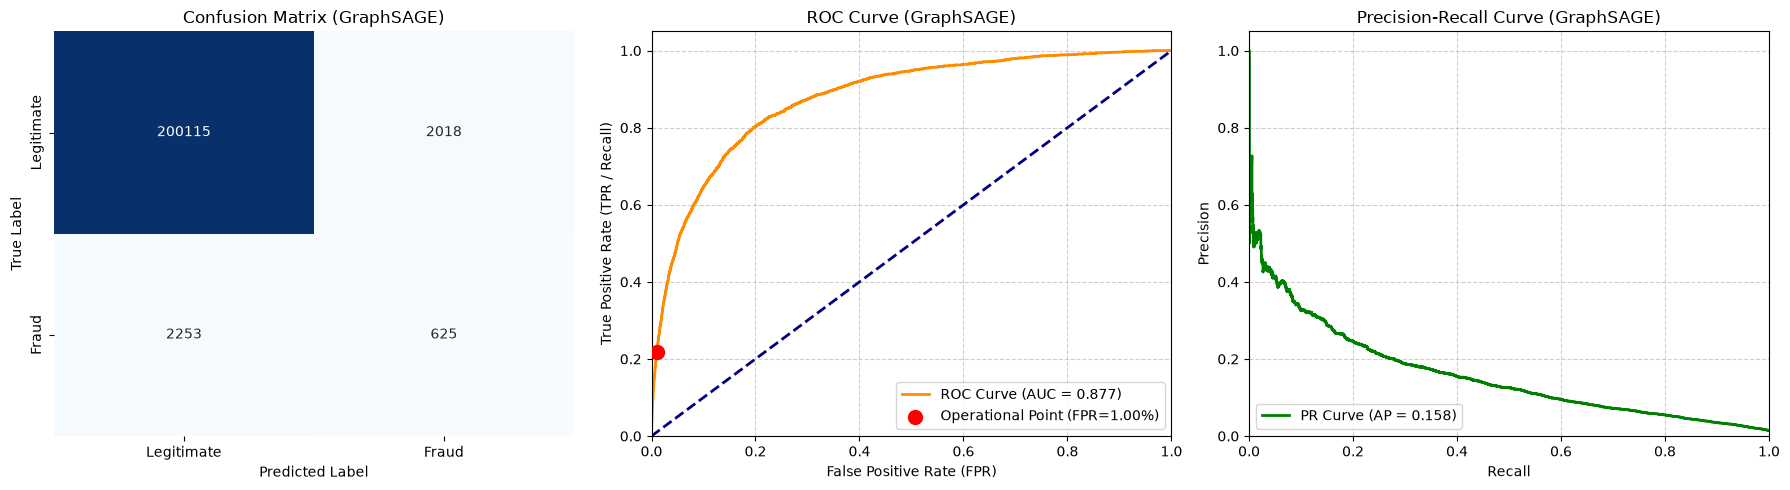

In [4]:
print("Evaluation report...")
evaluate_predictions(
    y_true=y_test_numpy,
    y_probs=test_probabilities,
    model_name="GraphSAGE"
)

In [ ]:
# Save the final GraphSAGE module weights structure securely
MODELS_DIR = Path(PROJECT_ROOT) / "models"
import os
os.makedirs(MODELS_DIR, exist_ok=True)

gs_save_path = MODELS_DIR / "graphsage_model.pt"
torch.save(model.state_dict(), str(gs_save_path))
print(f"GraphSAGE network layer weights saved to: {gs_save_path}")

GraphSAGE network layer weights saved to: C:\Users\shubh\projects\FairFraud\models\graphsage_model.pt
